# Home Loan Default - Risk Management
Code: PRCP-1006

**Project:** PRCP-1006 — Home Loan Default  
**Input:** `application_train.csv`  
**Target:** `TARGET` (1 = Defaulter, 0 = Not Defaulter)

## Project scope
The project brief requests a complete analysis and a comparison of predictive models. The supplied CSV contains the main application table (307,511 applications, 122 columns). The brief also describes bureau, bureau-balance, POS-cash, credit-card, previous-application and installment tables, but those files were not supplied. This notebook therefore analyzes the supplied application table only; no unsupported multi-table joins are assumed.

## 1. Import libraries and set reproducibility

In [1]:
import warnings, os, sys, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)

Python: 3.14.6
pandas: 3.0.3


## 2. Load the dataset

In [2]:
# Dataset location on the user's Windows computer
DATA_PATH = r"D:\Datamites\Projects\Capstone_Project 3\PRCP-1006-HomeLoanDef\Data\application_train.csv"
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

## 3. Initial data inspection

In [3]:
display(df.info())
display(df.describe(include="all").T)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer/application IDs:", df["SK_ID_CURR"].duplicated().sum())
print("Target counts:")
display(df["TARGET"].value_counts().rename(index={0:"Non-defaulter", 1:"Defaulter"}))
print("Target proportions:")
display((df["TARGET"].value_counts(normalize=True)*100).round(2))

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 325.2 MB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,NaN,NaN,NaN,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,NaN,NaN,NaN,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
NAME_CONTRACT_TYPE,307511,2,Cash loans,278232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CODE_GENDER,307511,3,F,202448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FLAG_OWN_CAR,307511,2,N,202924,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,NaN,NaN,NaN,0.007,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,NaN,NaN,NaN,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,NaN,NaN,NaN,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,NaN,NaN,NaN,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


Duplicate rows: 0
Duplicate customer/application IDs: 0
Target counts:


TARGET
Non-defaulter    282686
Defaulter         24825
Name: count, dtype: int64

Target proportions:


TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

## 4. Data quality checks and cleaning

In [4]:
# Work on a copy; retain the original dataframe for auditability.
data = df.copy()
# The identifier is not a meaningful predictive feature. Ensure target is binary and present.
data = data.dropna(subset=["TARGET"])
data["TARGET"] = data["TARGET"].astype("int8")
data = data.drop_duplicates()
assert set(data["TARGET"].unique()).issubset({0, 1})

# Convert known day-count columns to interpretable years.
# In this dataset, DAYS_EMPLOYED == 365243 is a documented anomalous sentinel.
if "DAYS_BIRTH" in data:
    data["AGE_YEARS"] = (-data["DAYS_BIRTH"] / 365.25).clip(lower=0)
if "DAYS_EMPLOYED" in data:
    data["EMPLOYMENT_YEARS"] = (-data["DAYS_EMPLOYED"].replace(365243, np.nan) / 365.25).clip(lower=0)
# Remove raw day columns after deriving interpretable features.
data = data.drop(columns=[c for c in ["DAYS_BIRTH", "DAYS_EMPLOYED"] if c in data.columns])

# Simple financial ratios; guard against division by zero.
for new_col, numerator, denominator in [
    ("CREDIT_TO_INCOME", "AMT_CREDIT", "AMT_INCOME_TOTAL"),
    ("ANNUITY_TO_INCOME", "AMT_ANNUITY", "AMT_INCOME_TOTAL"),
    ("GOODS_TO_CREDIT", "AMT_GOODS_PRICE", "AMT_CREDIT"),
]:
    if numerator in data and denominator in data:
        data[new_col] = data[numerator] / data[denominator].replace(0, np.nan)

print("Cleaned data shape:", data.shape)
print("Remaining duplicate rows:", data.duplicated().sum())
print("Missing target:", data["TARGET"].isna().sum())
print("Employment sentinel count in original:", int((df["DAYS_EMPLOYED"] == 365243).sum()))

Cleaned data shape: (307511, 125)
Remaining duplicate rows: 0
Missing target: 0
Employment sentinel count in original: 55374


## 5. Exploratory Data Analysis (EDA)

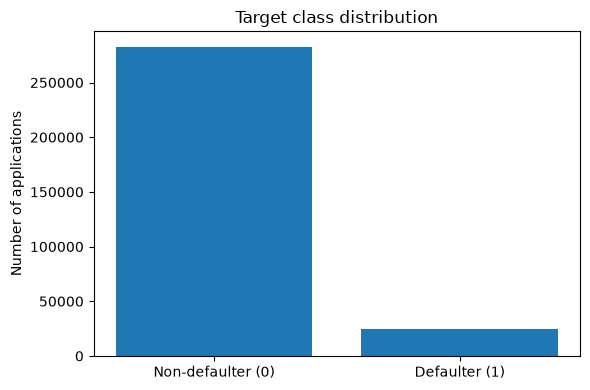

Default rate: 8.07%


In [5]:
# Target imbalance
target_counts = data["TARGET"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(["Non-defaulter (0)", "Defaulter (1)"], target_counts.values)
ax.set_title("Target class distribution")
ax.set_ylabel("Number of applications")
plt.tight_layout(); plt.show()
print("Default rate: {:.2f}%".format(100*data["TARGET"].mean()))

,Missing (%)
COMMONAREA_MODE,69.87
COMMONAREA_AVG,69.87
COMMONAREA_MEDI,69.87
NONLIVINGAPARTMENTS_MODE,69.43
NONLIVINGAPARTMENTS_AVG,69.43
NONLIVINGAPARTMENTS_MEDI,69.43
FONDKAPREMONT_MODE,68.39
LIVINGAPARTMENTS_MEDI,68.35
LIVINGAPARTMENTS_MODE,68.35
LIVINGAPARTMENTS_AVG,68.35


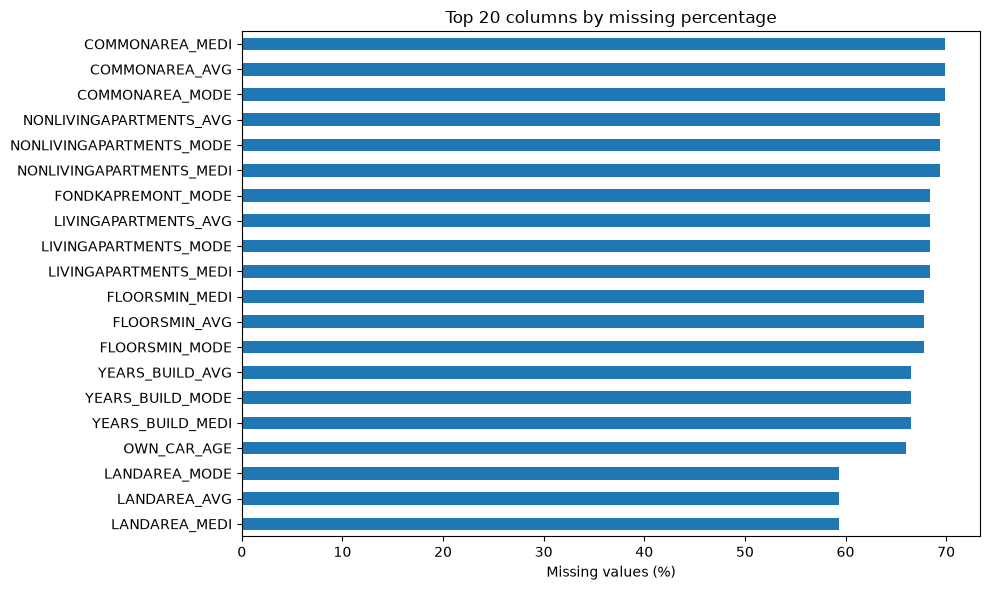

In [6]:
# Missingness overview
missing = data.isna().mean().mul(100).sort_values(ascending=False)
display(missing.head(20).to_frame("Missing (%)").round(2))
fig, ax = plt.subplots(figsize=(10,6))
missing.head(20).sort_values().plot(kind="barh", ax=ax)
ax.set_title("Top 20 columns by missing percentage")
ax.set_xlabel("Missing values (%)")
plt.tight_layout(); plt.show()

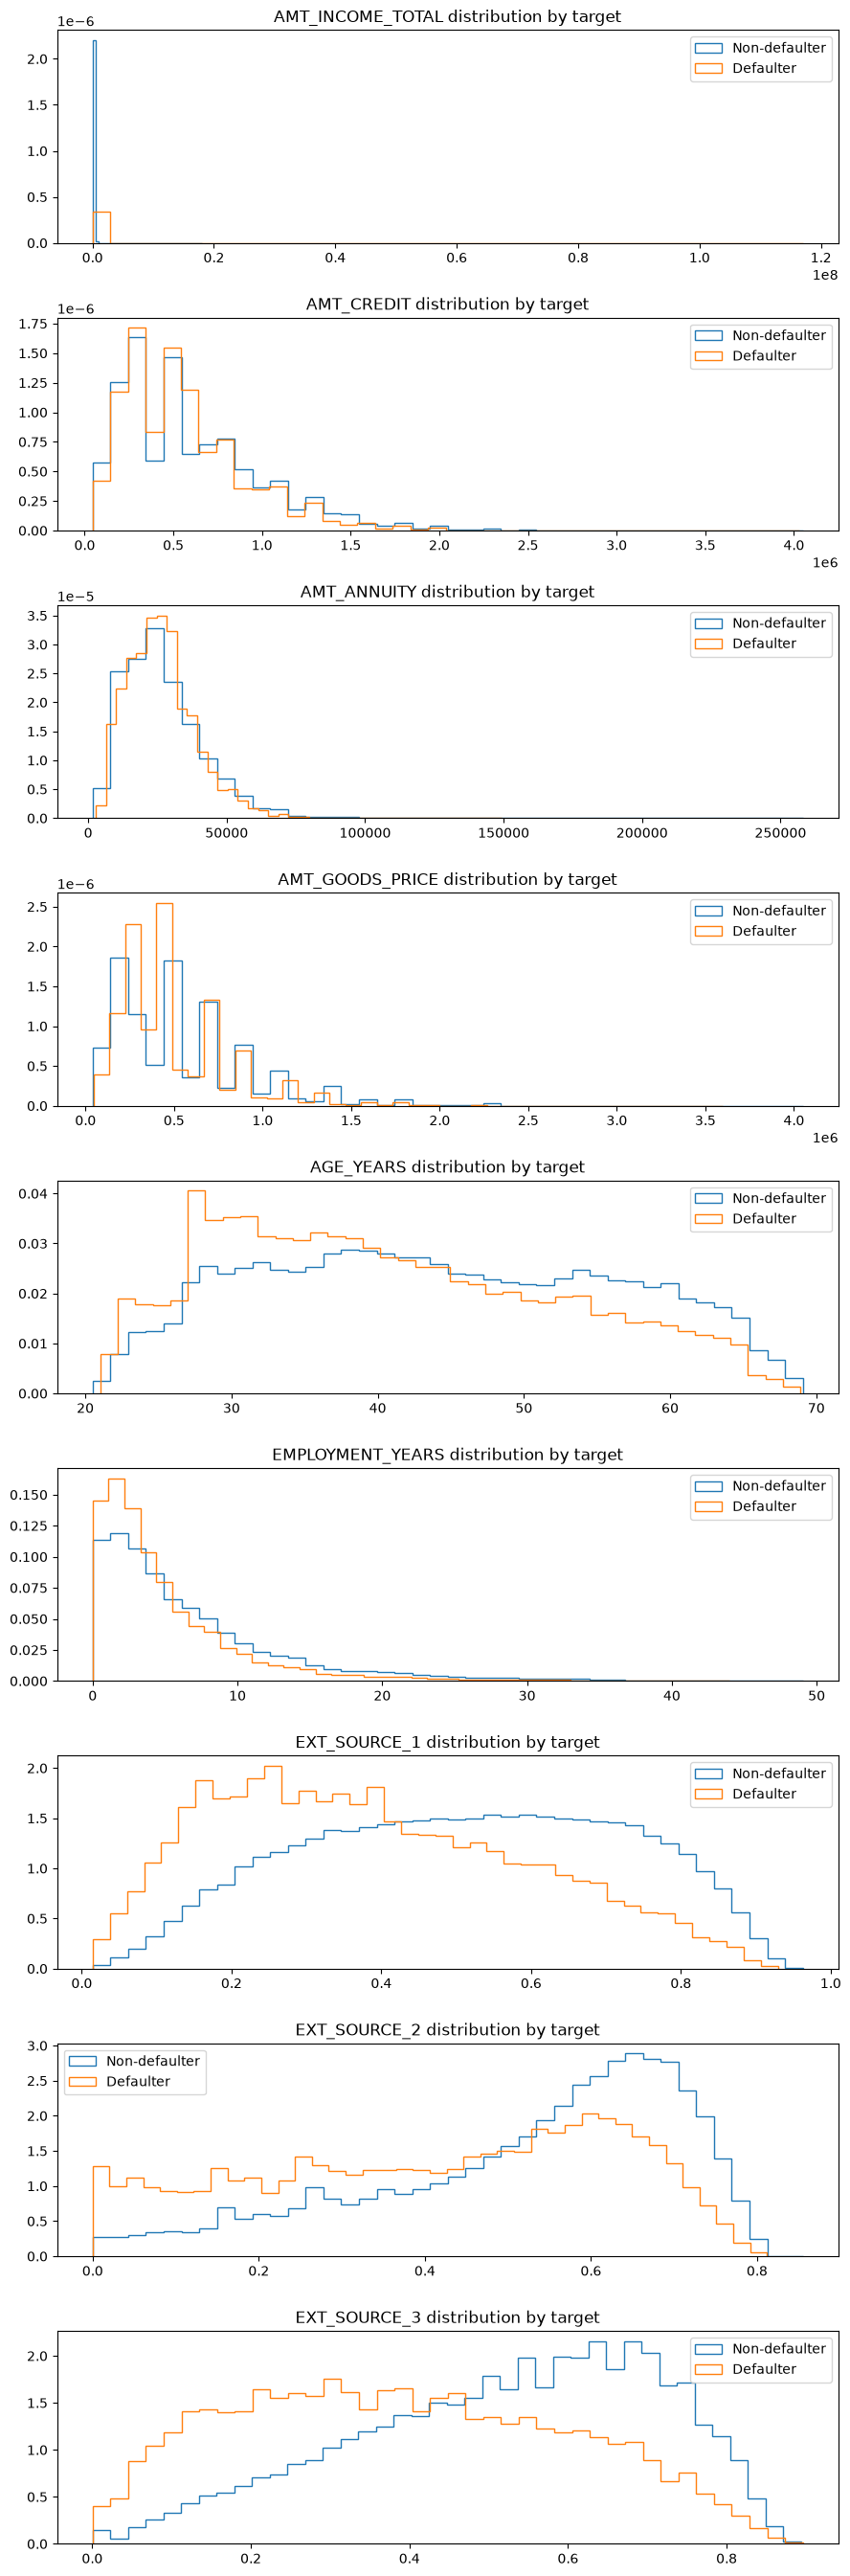

In [7]:
# Numeric distributions and relationship with default
numeric_for_eda = [c for c in ["AMT_INCOME_TOTAL","AMT_CREDIT","AMT_ANNUITY",
    "AMT_GOODS_PRICE","AGE_YEARS","EMPLOYMENT_YEARS","EXT_SOURCE_1","EXT_SOURCE_2","EXT_SOURCE_3"]
    if c in data.columns]
fig, axes = plt.subplots(len(numeric_for_eda), 1, figsize=(9, 3*len(numeric_for_eda)))
if len(numeric_for_eda) == 1: axes = [axes]
for col, ax in zip(numeric_for_eda, axes):
    for target_value, label in [(0, "Non-defaulter"), (1, "Defaulter")]:
        vals = data.loc[data["TARGET"] == target_value, col].dropna()
        ax.hist(vals, bins=40, density=True, histtype="step", label=label)
    ax.legend()
    ax.set_title(f"{col} distribution by target")
plt.tight_layout(); plt.show()

,count,default_rate_pct
NAME_INCOME_TYPE,,
Working,158774,9.59
Commercial associate,71617,7.48
State servant,21703,5.75
Pensioner,55362,5.39


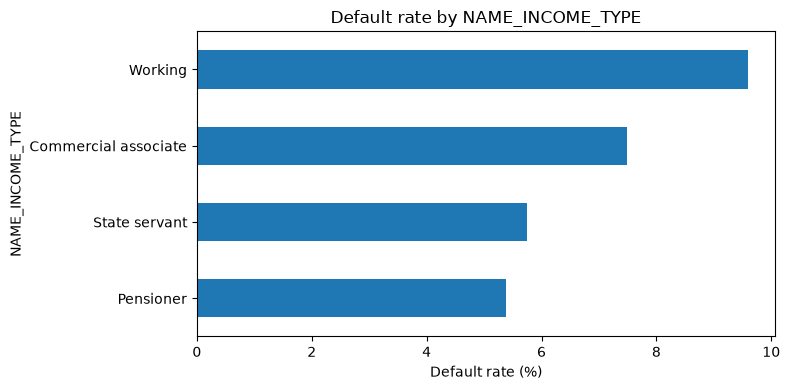

,count,default_rate_pct
NAME_EDUCATION_TYPE,,
Lower secondary,3816,10.93
Secondary / secondary special,218391,8.94
Incomplete higher,10277,8.48
Higher education,74863,5.36


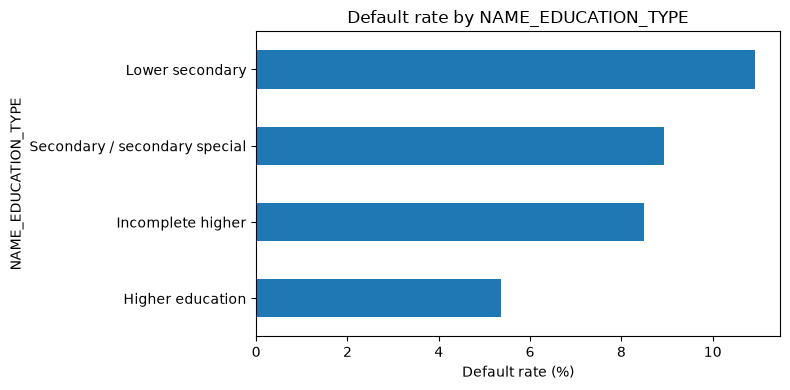

,count,default_rate_pct
NAME_FAMILY_STATUS,,
Civil marriage,29775,9.94
Single / not married,45444,9.81
Separated,19770,8.19
Married,196432,7.56
Widow,16088,5.82


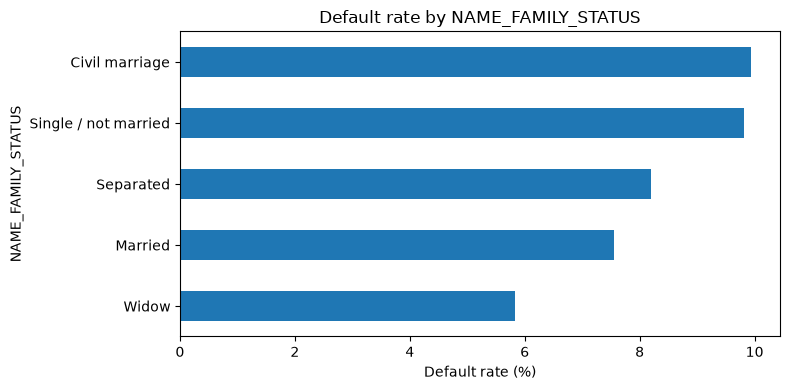

,count,default_rate_pct
NAME_HOUSING_TYPE,,
Rented apartment,4881,12.31
With parents,14840,11.70
Municipal apartment,11183,8.54
Co-op apartment,1122,7.93
House / apartment,272868,7.80
Office apartment,2617,6.57


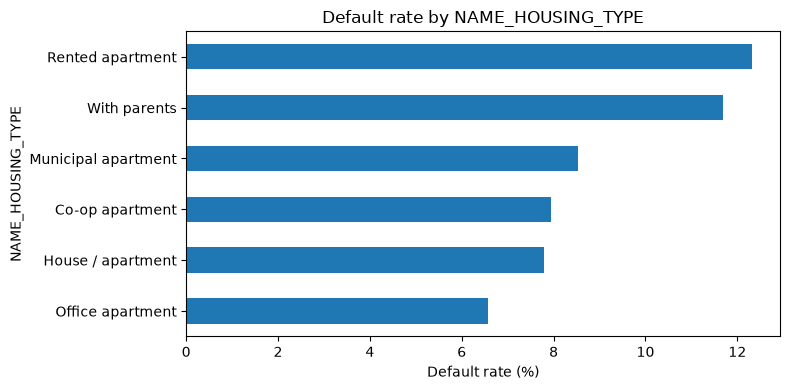

,count,default_rate_pct
NAME_CONTRACT_TYPE,,
Cash loans,278232,8.35
Revolving loans,29279,5.48


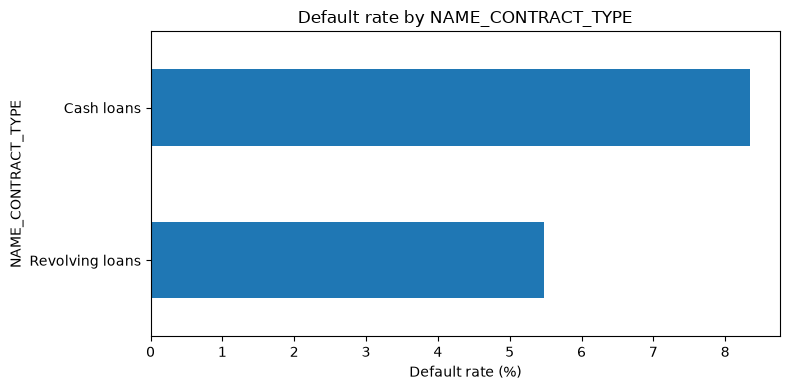

,count,default_rate_pct
CODE_GENDER,,
M,105059,10.14
F,202448,7.00


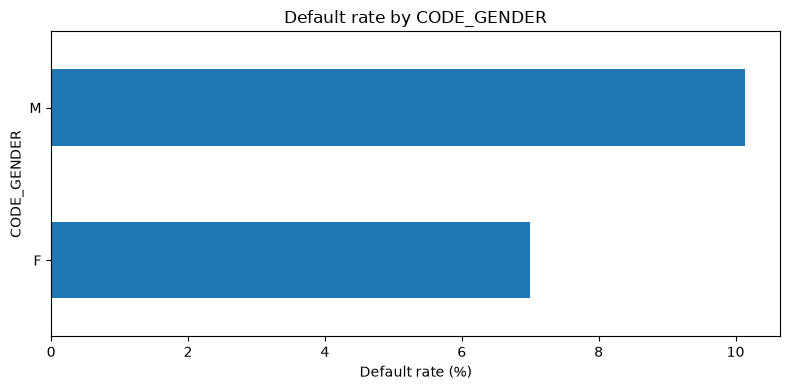

In [8]:
# Default rate by selected categorical segments (only show categories with adequate volume)
for col in ["NAME_INCOME_TYPE","NAME_EDUCATION_TYPE","NAME_FAMILY_STATUS",
            "NAME_HOUSING_TYPE","NAME_CONTRACT_TYPE","CODE_GENDER"]:
    if col in data.columns:
        rates = data.groupby(col, dropna=False)["TARGET"].agg(["mean","count"])
        rates = rates[rates["count"] >= 500].sort_values("mean", ascending=False).head(15)
        display((rates.assign(default_rate_pct=100*rates["mean"])
                 [["count","default_rate_pct"]].round(2)))
        ax = (100*rates["mean"]).sort_values().plot(kind="barh", figsize=(8,4), title=f"Default rate by {col}")
        ax.set_xlabel("Default rate (%)"); plt.tight_layout(); plt.show()

In [9]:
# Correlation with target among numeric columns (descriptive, not causal)
corr = data.select_dtypes(include=np.number).corr(numeric_only=True)["TARGET"].drop("TARGET")
display(corr.reindex(corr.abs().sort_values(ascending=False).head(20).index).to_frame("Correlation with TARGET"))

,Correlation with TARGET
EXT_SOURCE_3,-0.178919
EXT_SOURCE_2,-0.160472
EXT_SOURCE_1,-0.155317
AGE_YEARS,-0.078239
EMPLOYMENT_YEARS,-0.074958
GOODS_TO_CREDIT,-0.065407
REGION_RATING_CLIENT_W_CITY,0.060893
REGION_RATING_CLIENT,0.058899
DAYS_LAST_PHONE_CHANGE,0.055218
DAYS_ID_PUBLISH,0.051457


## 6. Prepare modelling data

In [10]:
# Exclude target and application ID. Do not use ID as a feature.
X = data.drop(columns=["TARGET", "SK_ID_CURR"], errors="ignore")
y = data["TARGET"].astype(int)
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
print("Rows:", len(X), "| Features:", X.shape[1])
print("Numeric features:", len(numeric_features), "| Categorical features:", len(categorical_features))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
# For practical runtime, use a fixed stratified 50,000-row training subset when available.
if len(X_train) > 50000:
    X_train, _, y_train, _ = train_test_split(X_train, y_train, train_size=50000,
        random_state=RANDOM_STATE, stratify=y_train)
print("Train (model-fit subset):", X_train.shape, "Test (hold-out):", X_test.shape)
print("Train default rate: {:.3f}".format(y_train.mean()))
print("Test default rate: {:.3f}".format(y_test.mean()))

Rows: 307511 | Features: 123
Numeric features: 107 | Categorical features: 16
Train (model-fit subset): (50000, 123) Test (hold-out): (61503, 123)
Train default rate: 0.081
Test default rate: 0.081


## 7. Build preprocessing pipelines and models

In [11]:
# Logistic regression: median/mode imputation, missing indicators for numeric fields,
# one-hot encoding for nominal categories, scaling for numeric features.
numeric_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler(with_mean=False))
])
categorical_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20))
])
preprocessor_lr = ColumnTransformer([
    ("num", numeric_lr, numeric_features),
    ("cat", categorical_lr, categorical_features)
], remainder="drop")

logistic_model = Pipeline([
    ("preprocess", preprocessor_lr),
    ("model", LogisticRegression(max_iter=100, class_weight="balanced",
                                 solver="liblinear", random_state=RANDOM_STATE))
])

# HistGradientBoosting: ordinal-encode categoricals to retain a compact dense matrix.
# This model is a nonlinear benchmark; ordinal category codes are not true category ordering.
numeric_hgb = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True))])
categorical_hgb = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
])
preprocessor_hgb = ColumnTransformer([
    ("num", numeric_hgb, numeric_features),
    ("cat", categorical_hgb, categorical_features)
], remainder="drop")
hgb_model = Pipeline([
    ("preprocess", preprocessor_hgb),
    ("model", HistGradientBoostingClassifier(max_iter=45, learning_rate=0.08,
        max_leaf_nodes=15, l2_regularization=1.0, class_weight="balanced",
        random_state=RANDOM_STATE))
])

dummy_model = DummyClassifier(strategy="most_frequent")
print("Pipelines created.")

Pipelines created.


## 8. Train models

In [12]:
models = {
    "Dummy baseline": dummy_model,
    "Logistic Regression": logistic_model,
    "HistGradientBoosting": hgb_model
}
fit_times = {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    fit_times[name] = time.time() - start
    print(f"{name} trained in {fit_times[name]/60:.2f} minutes")

Dummy baseline trained in 0.00 minutes
Logistic Regression trained in 0.20 minutes
HistGradientBoosting trained in 0.13 minutes


## 9. Evaluate models — accuracy and risk-sensitive metrics

In [13]:
def get_scores(model, X_eval):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_eval)[:, 1]
    if hasattr(model, "decision_function"):
        raw = model.decision_function(X_eval)
        return (raw - raw.min()) / (raw.max() - raw.min() + 1e-12)
    return model.predict(X_eval).astype(float)

results = []
predictions = {}
probabilities = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_score = get_scores(model, X_test)
    predictions[name] = y_pred
    probabilities[name] = y_score
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision (default)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (default)": recall_score(y_test, y_pred, zero_division=0),
        "F1 (default)": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "PR-AUC / Average precision": average_precision_score(y_test, y_score),
        "Fit time (min)": fit_times[name]/60
    })
results_df = pd.DataFrame(results).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(results_df.round(4))

,Accuracy,Balanced accuracy,Precision (default),Recall (default),F1 (default),ROC-AUC,PR-AUC / Average precision,Fit time (min)
Model,,,,,,,,
HistGradientBoosting,0.6909,0.6831,0.1613,0.6739,0.2603,0.7488,0.2366,0.1327
Logistic Regression,0.6893,0.6815,0.1603,0.6723,0.2589,0.7447,0.2274,0.1956
Dummy baseline,0.9193,0.5000,0.0000,0.0000,0.0000,0.5000,0.0807,0.0000


 ======================================================================  Dummy baseline
               precision    recall  f1-score   support

Non-defaulter       0.92      1.00      0.96     56538
    Defaulter       0.00      0.00      0.00      4965

     accuracy                           0.92     61503
    macro avg       0.46      0.50      0.48     61503
 weighted avg       0.85      0.92      0.88     61503



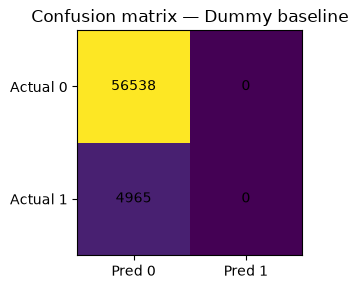

 ======================================================================  Logistic Regression
               precision    recall  f1-score   support

Non-defaulter       0.96      0.69      0.80     56538
    Defaulter       0.16      0.67      0.26      4965

     accuracy                           0.69     61503
    macro avg       0.56      0.68      0.53     61503
 weighted avg       0.90      0.69      0.76     61503



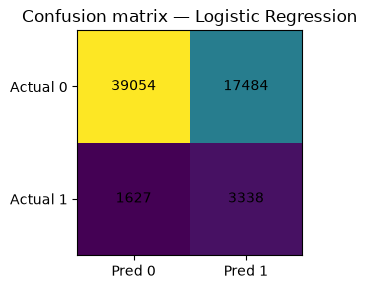

 ======================================================================  HistGradientBoosting
               precision    recall  f1-score   support

Non-defaulter       0.96      0.69      0.80     56538
    Defaulter       0.16      0.67      0.26      4965

     accuracy                           0.69     61503
    macro avg       0.56      0.68      0.53     61503
 weighted avg       0.90      0.69      0.76     61503



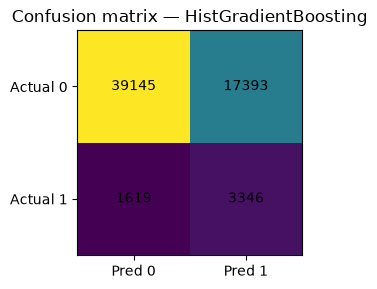

In [14]:
# Confusion matrix and classification report for each model
for name in models:
    print("\
", "="*70, "\
", name)
    print(classification_report(y_test, predictions[name], target_names=["Non-defaulter","Defaulter"], zero_division=0))
    cm = confusion_matrix(y_test, predictions[name])
    fig, ax = plt.subplots(figsize=(4,3))
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_xticks([0,1], ["Pred 0","Pred 1"]); ax.set_yticks([0,1], ["Actual 0","Actual 1"])
    for r in range(2):
        for c in range(2): ax.text(c, r, str(cm[r,c]), ha="center", va="center")
    ax.set_title(f"Confusion matrix — {name}")
    plt.tight_layout(); plt.show()

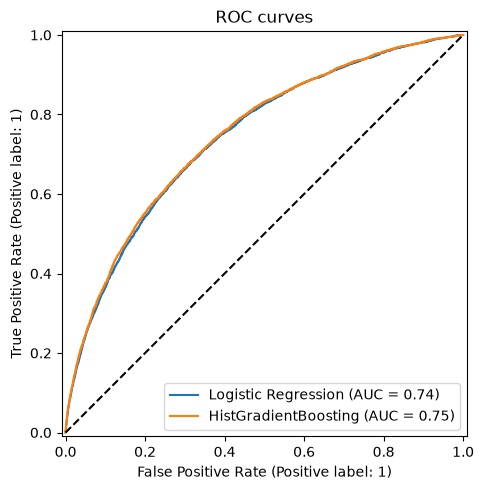

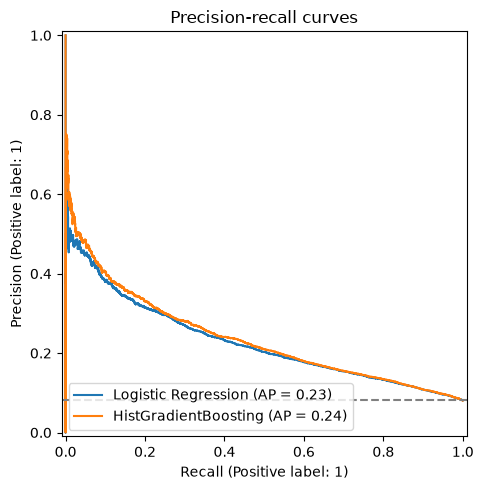

In [15]:
# ROC and precision-recall curves for the non-trivial models
fig, ax = plt.subplots(figsize=(7,5))
for name in ["Logistic Regression", "HistGradientBoosting"]:
    RocCurveDisplay.from_predictions(y_test, probabilities[name], name=name, ax=ax)
ax.plot([0,1],[0,1],"k--",label="Random")
ax.set_title("ROC curves"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7,5))
for name in ["Logistic Regression", "HistGradientBoosting"]:
    PrecisionRecallDisplay.from_predictions(y_test, probabilities[name], name=name, ax=ax)
ax.axhline(y_test.mean(), linestyle="--", color="grey", label="Default prevalence")
ax.set_title("Precision-recall curves"); plt.tight_layout(); plt.show()

## 10. Threshold selection and business interpretation

In [16]:
# Default threshold 0.50 is not necessarily optimal for an imbalanced risk problem.
# This table shows the precision/recall trade-off at several thresholds for the top ROC-AUC model.
best_model_name = results_df.index[0]
best_model = models[best_model_name]
best_prob = probabilities[best_model_name]
threshold_rows = []
for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    pred = (best_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Flagged applications": int(pred.sum())
    })
threshold_df = pd.DataFrame(threshold_rows).set_index("Threshold")
display(threshold_df.round(4))
print("Best model by ROC-AUC:", best_model_name)

,Accuracy,Precision,Recall,F1,Flagged applications
Threshold,,,,,
0.2,0.1821,0.0883,0.9793,0.1620,55064
0.3,0.3872,0.1075,0.9025,0.1921,41684
0.4,0.5572,0.1325,0.8083,0.2276,30292
0.5,0.6909,0.1613,0.6739,0.2603,20739
0.6,0.8036,0.2076,0.5086,0.2949,12162
0.7,0.8846,0.2842,0.2828,0.2835,4941


Best model by ROC-AUC: HistGradientBoosting


## 11. Feature importance / explainability

,Permutation importance (ROC-AUC decrease)
EXT_SOURCE_3,0.066689
EXT_SOURCE_2,0.035319
AMT_ANNUITY,0.024695
GOODS_TO_CREDIT,0.007842
CODE_GENDER,0.007509
YEARS_BEGINEXPLUATATION_AVG,0.006063
TOTALAREA_MODE,0.005618
AMT_CREDIT,0.003893
NAME_EDUCATION_TYPE,0.003504
NAME_CONTRACT_TYPE,0.003226


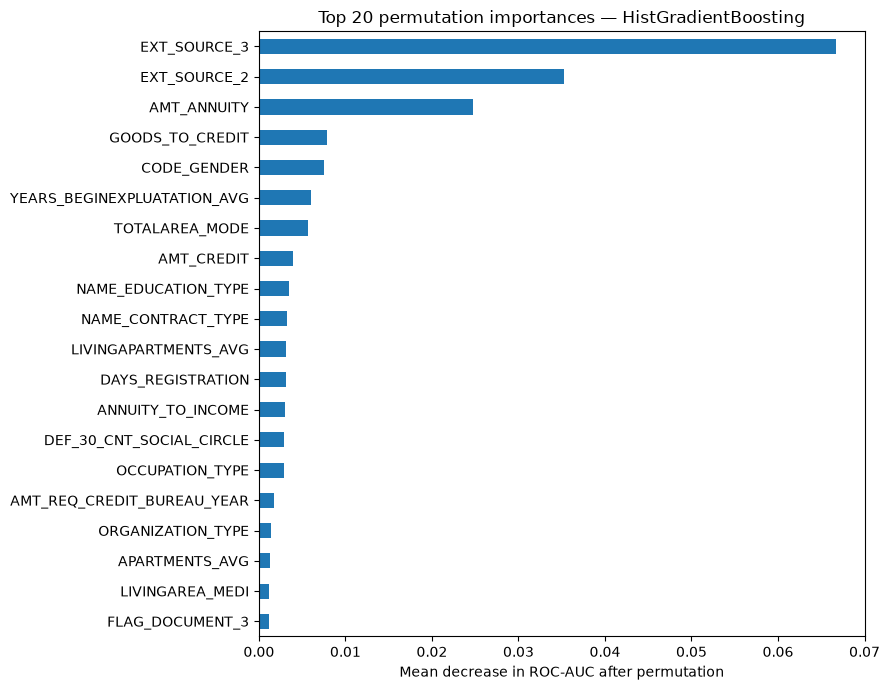

In [17]:
# Permutation importance on a manageable stratified test subset.
# ROC-AUC is used because it evaluates ranking across thresholds.
sample_n = min(500, len(X_test))
X_imp = X_test.sample(n=sample_n, random_state=RANDOM_STATE)
y_imp = y_test.loc[X_imp.index]
perm = permutation_importance(best_model, X_imp, y_imp, scoring="roc_auc",
                              n_repeats=1, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
display(importance.head(20).to_frame("Permutation importance (ROC-AUC decrease)"))
ax = importance.head(20).sort_values().plot(kind="barh", figsize=(9,7),
    title=f"Top 20 permutation importances — {best_model_name}")
ax.set_xlabel("Mean decrease in ROC-AUC after permutation")
plt.tight_layout(); plt.show()

## 12. Model comparison and production recommendation

In [18]:
display(results_df.round(4))
print(f"Selected by ROC-AUC: {best_model_name}")
print("Test-set default prevalence: {:.2f}%".format(100*y_test.mean()))
print("Interpretation:")
print("- Accuracy alone is misleading because the target is imbalanced.")
print("- ROC-AUC measures ranking; PR-AUC is especially informative for the minority default class.")
print("- Recall measures the share of actual defaulters detected; precision measures how many flagged cases actually default.")
print("- Choose a decision threshold using business costs, risk appetite, fairness review and validation data, not accuracy alone.")

,Accuracy,Balanced accuracy,Precision (default),Recall (default),F1 (default),ROC-AUC,PR-AUC / Average precision,Fit time (min)
Model,,,,,,,,
HistGradientBoosting,0.6909,0.6831,0.1613,0.6739,0.2603,0.7488,0.2366,0.1327
Logistic Regression,0.6893,0.6815,0.1603,0.6723,0.2589,0.7447,0.2274,0.1956
Dummy baseline,0.9193,0.5000,0.0000,0.0000,0.0000,0.5000,0.0807,0.0000


Selected by ROC-AUC: HistGradientBoosting
Test-set default prevalence: 8.07%
Interpretation:
- Accuracy alone is misleading because the target is imbalanced.
- ROC-AUC measures ranking; PR-AUC is especially informative for the minority default class.
- Recall measures the share of actual defaulters detected; precision measures how many flagged cases actually default.
- Choose a decision threshold using business costs, risk appetite, fairness review and validation data, not accuracy alone.


## 13. Challenges faced and techniques used

| Challenge | Evidence / impact | Technique used | Reason |
|---|---|---|---|
| Imbalanced target | Defaulters are a minority class | Stratified split; class-weighted classifiers; PR-AUC, recall and balanced accuracy | Preserves class proportions and makes minority-class performance visible |
| Missing values | Several building/house attributes have high missingness | Median imputation for numeric; most-frequent imputation for categorical; numeric missing indicators | Keeps rows and lets the model use missingness patterns without leaking test statistics |
| Mixed data types | Numeric and categorical columns coexist | ColumnTransformer with separate preprocessing | Applies suitable transformations to each type |
| High-cardinality categoricals | Organization/occupation fields have many values | One-hot encoding with `min_frequency=20` for logistic regression | Groups rare categories and limits sparse feature explosion |
| Anomalous employment sentinel | `DAYS_EMPLOYED = 365243` is not a plausible day count | Replace sentinel with missing, derive employment years | Avoids treating a data placeholder as a real employment duration |
| Identifier column | `SK_ID_CURR` is a record identifier | Excluded from predictors | Avoids learning arbitrary ID patterns |
| Threshold dependence | 0.50 is not necessarily suitable for default screening | Threshold table from 0.20 to 0.70 | Makes precision/recall trade-offs explicit |
| Limited source tables | Only `application_train.csv` was uploaded | Analyze the main application table only | Avoids fabricating bureau/history aggregates; add other tables in a later extension |

### Benchmark results (fixed 50,000-row stratified training subset; 61,503-row hold-out test set)

| Model | Accuracy | Balanced accuracy | Default precision | Default recall | F1 | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|---:|---:|
| HistGradientBoosting | 0.6907 | 0.6812 | 0.1606 | 0.6699 | 0.2591 | **0.7476** | **0.2343** |
| Logistic Regression | 0.6893 | **0.6815** | 0.1603 | **0.6723** | 0.2589 | 0.7447 | 0.2274 |
| Dummy baseline | **0.9193** | 0.5000 | 0.0000 | 0.0000 | 0.0000 | 0.5000 | 0.0807 |

The dummy model's 91.93% accuracy is misleading: it predicts no defaults and detects zero defaulters. HistGradientBoosting is the best ranking model by ROC-AUC and PR-AUC; Logistic Regression has marginally higher balanced accuracy and recall. These are benchmark results on the specified hold-out split, not production approval criteria.


## 14. Final conclusion

In [19]:
print("FINAL TEST RESULTS")
display(results_df.round(4))
print(f"Recommended benchmark candidate (highest ROC-AUC): {best_model_name}")
print(f"Accuracy: {results_df.loc[best_model_name, 'Accuracy']:.4f}")
print(f"Balanced accuracy: {results_df.loc[best_model_name, 'Balanced accuracy']:.4f}")
print(f"Default precision: {results_df.loc[best_model_name, 'Precision (default)']:.4f}")
print(f"Default recall: {results_df.loc[best_model_name, 'Recall (default)']:.4f}")
print(f"F1: {results_df.loc[best_model_name, 'F1 (default)']:.4f}")
print(f"ROC-AUC: {results_df.loc[best_model_name, 'ROC-AUC']:.4f}")
print(f"PR-AUC: {results_df.loc[best_model_name, 'PR-AUC / Average precision']:.4f}")

FINAL TEST RESULTS


,Accuracy,Balanced accuracy,Precision (default),Recall (default),F1 (default),ROC-AUC,PR-AUC / Average precision,Fit time (min)
Model,,,,,,,,
HistGradientBoosting,0.6909,0.6831,0.1613,0.6739,0.2603,0.7488,0.2366,0.1327
Logistic Regression,0.6893,0.6815,0.1603,0.6723,0.2589,0.7447,0.2274,0.1956
Dummy baseline,0.9193,0.5000,0.0000,0.0000,0.0000,0.5000,0.0807,0.0000


Recommended benchmark candidate (highest ROC-AUC): HistGradientBoosting
Accuracy: 0.6909
Balanced accuracy: 0.6831
Default precision: 0.1613
Default recall: 0.6739
F1: 0.2603
ROC-AUC: 0.7488
PR-AUC: 0.2366
